## 1. Verilənləri oxumaq və təmizləmək

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA, TruncatedSVD
from scipy.cluster.hierarchy import linkage, dendrogram

df = pd.read_csv("/content/drive/MyDrive/datasets/OnlineRetail.csv", encoding="latin-1")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom


In [4]:
df = df.dropna(subset=["CustomerID"])
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], format="%d-%m-%Y %H:%M")
df["Total"] = df["Quantity"] * df["UnitPrice"]

print("Təmizləndikdən sonra:", df.shape[0], "sətir,", df["CustomerID"].nunique(), "müştəri")

Təmizləndikdən sonra: 397884 sətir, 4338 müştəri


## 2. 25 000

In [5]:
son_tarix = df["InvoiceDate"].max() + pd.Timedelta(days=1)
data = df.sample(n=25000, random_state=42)

## 3. Müştəri səviyyəsində göstəricilər (RFM)
Hər müştəri üçün 3 göstərici hesablayırıq:
- **alis_tezliyi** — neçə dəfə alış-veriş edib (fərqli faktura sayı)
- **son_alisdan_gun** — axırıncı alışdan neçə gün keçib
- **xerclenen_mebleg** — ümumi nə qədər pul xərcləyib

In [6]:
musteri = data.groupby("CustomerID").agg(
    alis_tezliyi=("InvoiceNo", "nunique"),
    son_alisdan_gun=("InvoiceDate", lambda x: (son_tarix - x.max()).days),
    xerclenen_mebleg=("Total", "sum")
).round(1)

musteri.head()

,alis_tezliyi,son_alisdan_gun,xerclenen_mebleg
CustomerID,,,
12347.0,7,2,412.8
12348.0,2,319,153.1
12349.0,1,19,106.0
12350.0,1,310,65.2
12352.0,7,36,520.2


In [7]:
musteri.describe().round(1)

,alis_tezliyi,son_alisdan_gun,xerclenen_mebleg
count,3482.0,3482.0,3482.0
mean,3.1,100.9,152.7
std,5.1,101.8,578.8
min,1.0,1.0,0.6
25%,1.0,22.0,22.5
50%,2.0,60.0,53.8
75%,4.0,159.0,130.0
max,136.0,374.0,16154.3


## 4. Verilənlərin hazırlanması

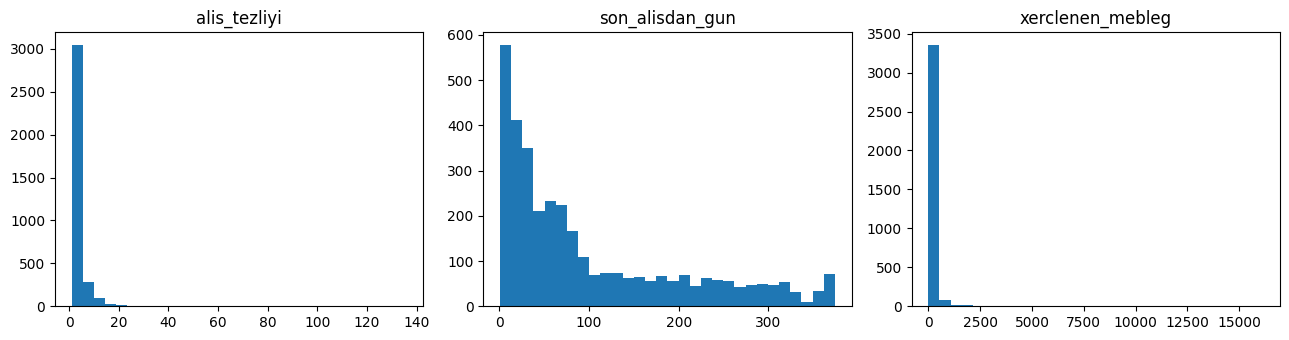

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
for i, s in enumerate(musteri.columns):
    ax[i].hist(musteri[s], bins=30); ax[i].set_title(s)
plt.tight_layout(); plt.show()

In [9]:
X = np.log1p(musteri)                       # loqarifm
X = StandardScaler().fit_transform(X)       # miqyaslama

## 5. K-means: optimal klaster sayının seçilməsi

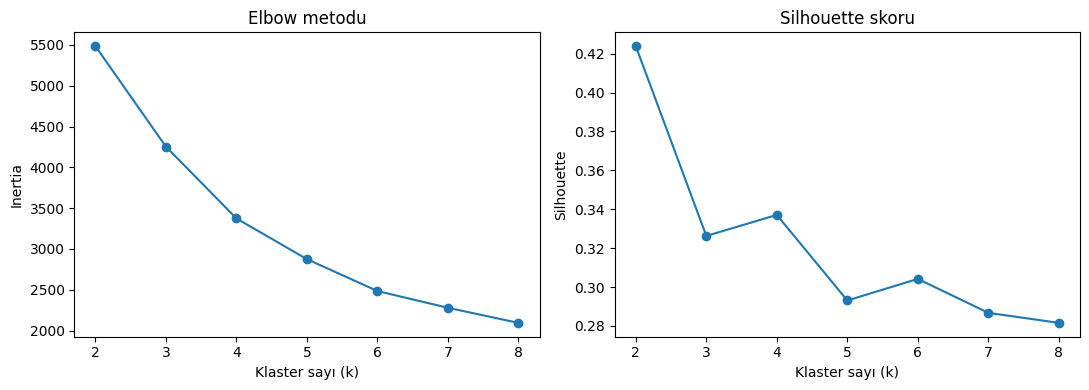

In [10]:
inertia, silhouette = [], []
K = range(2, 9)

for k in K:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X, labels))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(K, inertia, "o-"); ax[0].set(xlabel="Klaster sayı (k)", ylabel="Inertia", title="Elbow metodu")
ax[1].plot(K, silhouette, "o-"); ax[1].set(xlabel="Klaster sayı (k)", ylabel="Silhouette", title="Silhouette skoru")
plt.tight_layout(); plt.show()

## 6. K-means (k = 4)

In [11]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
musteri["kmeans_klaster"] = kmeans.fit_predict(X)

print("Silhouette skoru:", round(silhouette_score(X, musteri["kmeans_klaster"]), 3))
print("\nHər klasterdə müştəri sayı:")
print(musteri["kmeans_klaster"].value_counts().sort_index())

musteri.groupby("kmeans_klaster")[["alis_tezliyi", "son_alisdan_gun", "xerclenen_mebleg"]].mean().round(1)

Silhouette skoru: 0.337

Hər klasterdə müştəri sayı:
kmeans_klaster
0    1394
1     487
2     660
3     941
Name: count, dtype: int64


,alis_tezliyi,son_alisdan_gun,xerclenen_mebleg
kmeans_klaster,,,
0,1.2,183.6,30.5
1,9.9,13.8,631.0
2,1.8,19.0,44.7
3,3.3,81.0,162.0


## 7. İerarxik klasterləşdirmə

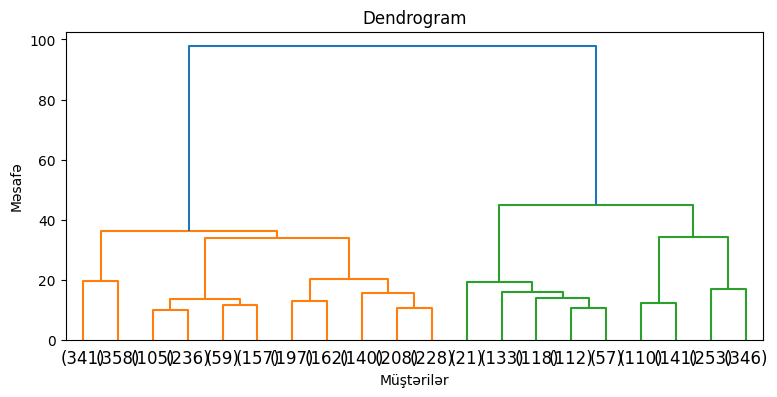

In [12]:
Z = linkage(X, method="ward")

plt.figure(figsize=(9, 4))
dendrogram(Z, truncate_mode="lastp", p=20)
plt.title("Dendrogram"); plt.xlabel("Müştərilər"); plt.ylabel("Məsafə")
plt.show()

In [13]:
hier = AgglomerativeClustering(n_clusters=4, linkage="ward")
musteri["hier_klaster"] = hier.fit_predict(X)

print("Silhouette skoru:", round(silhouette_score(X, musteri["hier_klaster"]), 3))
pd.crosstab(musteri["kmeans_klaster"], musteri["hier_klaster"])

Silhouette skoru: 0.218


hier_klaster,0,1,2,3
kmeans_klaster,,,,
0,0,695,0,699
1,55,1,431,0
2,265,392,3,0
3,530,404,7,0


## 8. PCA (ölçülərin azaldılması)

Izah olunan variasiya: [0.71  0.212]
Cəmi: 0.922


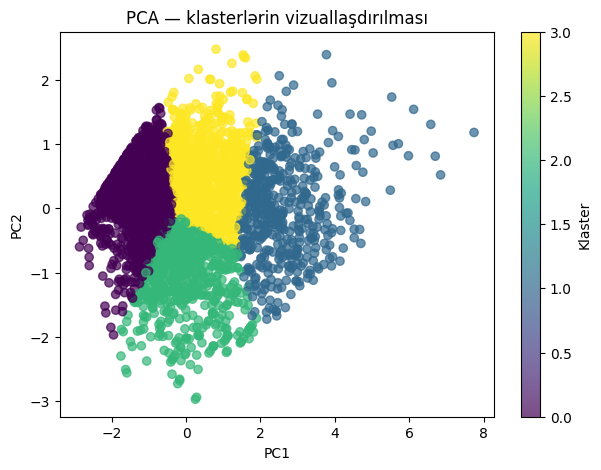

In [14]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

print("Izah olunan variasiya:", pca.explained_variance_ratio_.round(3))
print("Cəmi:", round(pca.explained_variance_ratio_.sum(), 3))

plt.figure(figsize=(7, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=musteri["kmeans_klaster"], cmap="viridis", alpha=0.7)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("PCA — klasterlərin vizuallaşdırılması")
plt.colorbar(label="Klaster"); plt.show()

## 9. SVD

Izah olunan variasiya: [0.71  0.212]
Cəmi: 0.922


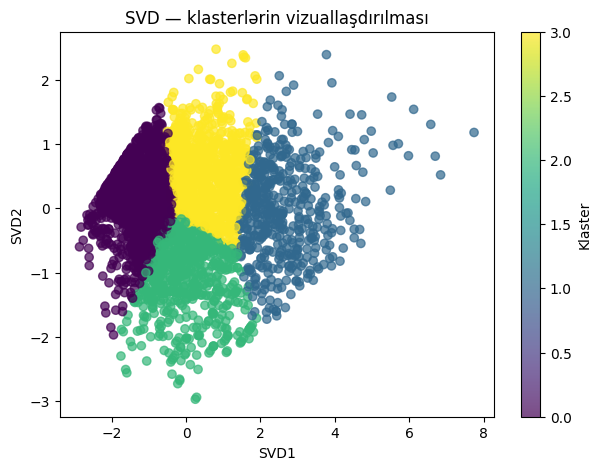

In [15]:
svd = TruncatedSVD(n_components=2, random_state=42)
X_svd = svd.fit_transform(X)

print("Izah olunan variasiya:", svd.explained_variance_ratio_.round(3))
print("Cəmi:", round(svd.explained_variance_ratio_.sum(), 3))

plt.figure(figsize=(7, 5))
plt.scatter(X_svd[:, 0], X_svd[:, 1], c=musteri["kmeans_klaster"], cmap="viridis", alpha=0.7)
plt.xlabel("SVD1"); plt.ylabel("SVD2"); plt.title("SVD — klasterlərin vizuallaşdırılması")
plt.colorbar(label="Klaster"); plt.show()